In [388]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

In [389]:
df=pd.read_csv("insurance.csv")

In [390]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [391]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [392]:
df.describe

<bound method NDFrame.describe of       age     sex     bmi  children smoker     region      charges
0      19  female  27.900         0    yes  southwest  16884.92400
1      18    male  33.770         1     no  southeast   1725.55230
2      28    male  33.000         3     no  southeast   4449.46200
3      33    male  22.705         0     no  northwest  21984.47061
4      32    male  28.880         0     no  northwest   3866.85520
...   ...     ...     ...       ...    ...        ...          ...
1333   50    male  30.970         3     no  northwest  10600.54830
1334   18  female  31.920         0     no  northeast   2205.98080
1335   18  female  36.850         0     no  southeast   1629.83350
1336   21  female  25.800         0     no  southwest   2007.94500
1337   61  female  29.070         0    yes  northwest  29141.36030

[1338 rows x 7 columns]>

In [393]:
df.shape

(1338, 7)

In [394]:
df.dtypes

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

In [395]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [396]:
df.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [397]:
df.notnull()

,age,sex,bmi,children,smoker,region,charges
0,True,True,True,True,True,True,True
1,True,True,True,True,True,True,True
2,True,True,True,True,True,True,True
3,True,True,True,True,True,True,True
4,True,True,True,True,True,True,True
...,...,...,...,...,...,...,...
1333,True,True,True,True,True,True,True
1334,True,True,True,True,True,True,True
1335,True,True,True,True,True,True,True
1336,True,True,True,True,True,True,True


In [398]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [399]:
rm_z_scores = np.abs(stats.zscore(df['charges']))
outliers_z = df[rm_z_scores > 3]
print(f"Z-Score Method found {len(outliers_z)} outliers in the 'charges' column.")

Z-Score Method found 7 outliers in the 'charges' column.


In [400]:
label=LabelEncoder()
df['sex']=label.fit_transform(df['sex'])
df['smoker']=label.fit_transform(df['smoker'])
df['region']=label.fit_transform(df['region'])
df

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,3,16884.92400
1,18,1,33.770,1,0,2,1725.55230
2,28,1,33.000,3,0,2,4449.46200
3,33,1,22.705,0,0,1,21984.47061
4,32,1,28.880,0,0,1,3866.85520
...,...,...,...,...,...,...,...
1333,50,1,30.970,3,0,1,10600.54830
1334,18,0,31.920,0,0,0,2205.98080
1335,18,0,36.850,0,0,2,1629.83350
1336,21,0,25.800,0,0,3,2007.94500


In [401]:
X = df[['bmi']]
y = df['charges']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Samples :", len(X_train))
print("Testing Samples :", len(X_test))

Training Samples : 1070
Testing Samples : 268


In [402]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)


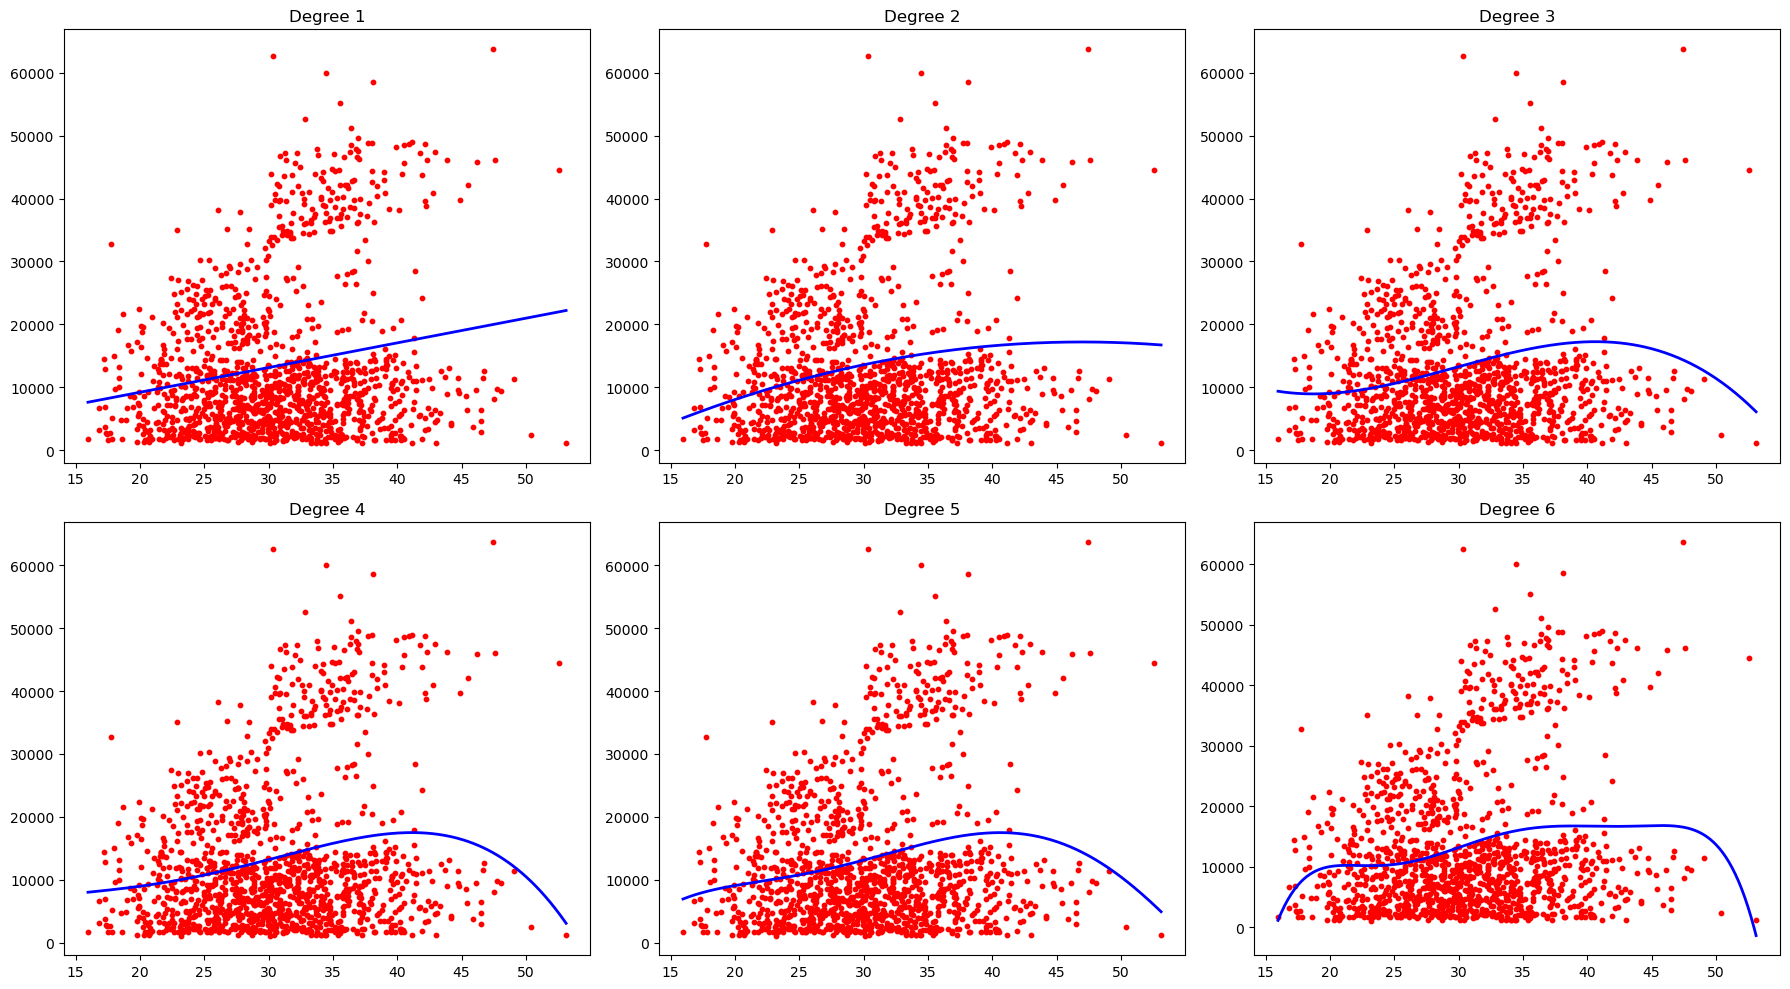

In [407]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

degrees = [1, 2, 3, 4, 5, 6]
results = []  # Keep this initialization here

plt.figure(figsize=(18, 10))
x_grid = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)

for degree in degrees:
    poly = PolynomialFeatures(degree)
    X_poly_train = poly.fit_transform(X_train)
    
    model = LinearRegression()
    model.fit(X_poly_train, y_train)
    
    y_pred = model.predict(poly.transform(X_test))
    
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    # REMOVED 'results = []' from here to avoid overwriting
    results.append([degree, mse, rmse, r2])
    
    plt.subplot(2, 3, degree)
    plt.scatter(X, y, color='red', s=10)
    plt.plot(x_grid, model.predict(poly.transform(x_grid)), color='blue', linewidth=2)
    plt.title(f"Degree {degree}")

# Moved outside the for loop to display all 6 subplots at once
plt.tight_layout()
plt.show()


In [410]:
results_df=pd.DataFrame(results,columns=["Degree","MSE","RMSE","r2 Score"])
results_df

,Degree,MSE,RMSE,r2 Score
0,1,1.490851e+08,12210.039191,0.039702
1,2,1.504728e+08,12266.733504,0.030763
2,3,1.524525e+08,12347.166300,0.018011
3,4,1.531528e+08,12375.489932,0.013501
4,5,1.526792e+08,12356.343312,0.016551
5,6,1.538508e+08,12403.660283,0.009005


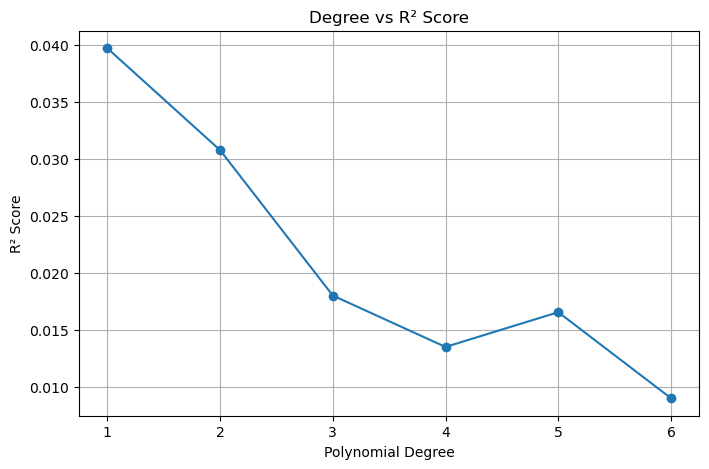

In [411]:
plt.figure(figsize=(8,5))
plt.plot(results_df["Degree"],results_df["r2 Score"],marker='o')
plt.xlabel("Polynomial Degree")
plt.ylabel("R² Score")
plt.title("Degree vs R² Score")
plt.grid(True)
plt.show()

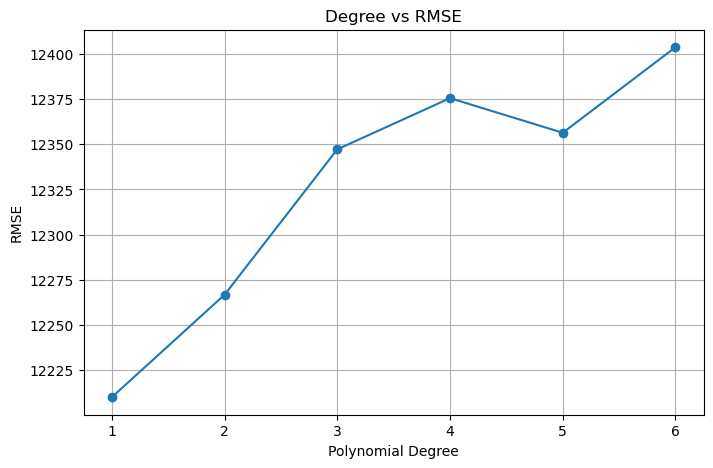

In [412]:
plt.figure(figsize=(8,5))
plt.plot(results_df["Degree"],results_df["RMSE"],marker='o')
plt.xlabel("Polynomial Degree")
plt.ylabel("RMSE")
plt.title("Degree vs RMSE")
plt.grid(True)
plt.show()
